# Feature selection — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D006_C5_Feature_Selection.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# Chapter 5: Feature Selection

> **Data** wine_types.csv  (exercises use clinic_biomarkers.csv) · **Time** 45 min · **Needs first** C2, C4, cross-validation

## What you will be able to do

1. Remove redundant features with a correlation matrix and VarianceThreshold
2. Rank features with SelectKBest and say which score function suits the data
3. Use RFE and SelectFromModel, and state how they differ from a filter
4. Read tree feature_importances_ and name a case where it misleads
5. Put a selector inside a Pipeline so it refits on every fold

## The one idea to hold on to

Selection is part of the model. Do it outside the split and you are not measuring the model any more, you are measuring your own peek at the answers.

Feature selection is the process of selecting a subset of relevant features from the original dataset to improve machine learning model performance. By removing noise and reducing dimensionality, we can achieve better accuracy and faster training times.

---

## Introduction: Why Feature Selection?

When working with datasets, we often encounter **noise** - features that do not contribute to predicting the target variable and may even hurt model performance. Feature selection helps us address several challenges:

### The Curse of Dimensionality

As the number of features increases, the amount of data needed to generalize accurately grows exponentially. This phenomenon is known as the **curse of dimensionality**.

![Curse of Dimensionality](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fcdn-images-1.medium.com%2Fmax%2F1600%2F1*kpNRfZ9DgkNPf_dA6DukLw.png&f=1&nofb=1&ipt=fa21107ffecccea5251dae3be0eb034d80f5594c79da31f7911c9091339f390f)

*As dimensions increase, data becomes increasingly sparse, making pattern recognition harder.*

### Benefits of Feature Selection

| Benefit | Description |
| :--- | :--- |
| **Improved Accuracy** | Removing irrelevant features helps models focus on signal, not noise |
| **Reduced Training Time** | Fewer features means faster model fitting and prediction |
| **Reduced Overfitting** | Simpler models generalize better to new data |
| **Better Interpretability** | Easier to understand which features drive predictions |
| **Lower Storage Requirements** | Less data to store and process |

---

## Types of Feature Selection Methods

Feature selection methods can be categorized into three main types:

![Feature Selection Types](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fwww.baeldung.com%2Fwp-content%2Fuploads%2Fsites%2F4%2F2022%2F11%2FFeature_Selection_Methods.png&f=1&nofb=1&ipt=fda08c86e8bdfe4aa57d724a1e3d6d8b5340b6a551200f031f07302c0e686bb6)

*Overview of different feature selection approaches.*

1. **Filter Methods**: Select features based on statistical measures (correlation, chi-squared, ANOVA)
   - Pros: Fast, model-independent
   - Cons: Ignores feature interactions

2. **Wrapper Methods**: Use a model to evaluate feature subsets (RFE, forward/backward selection)
   - Pros: Considers feature interactions
   - Cons: Computationally expensive

3. **Embedded Methods**: Feature selection happens during model training (L1 regularization, tree importance)
   - Pros: Efficient, considers interactions
   - Cons: Model-specific

In [ ]:
# TODO: call `warnings.filterwarnings`

---

## 1. Loading and Exploring the Dataset

We will use the wine dataset to demonstrate feature selection techniques. This dataset contains various chemical properties of wines that we can use to predict wine types.

### Understanding Our Data

Before applying feature selection, it is essential to understand what each feature represents. Domain knowledge helps us make informed decisions about which features might be relevant.

In [ ]:
# TODO: compute `df`
# Name your result: df

In [3]:
# Display first few rows
df.head()

,Type,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [4]:
# Check for missing values
print("Missing Values:")
print(df.isnull().sum())

# Descriptive statistics
print("\nDescriptive Statistics:")
df.describe().round(2)

Missing Values:
Type                            0
Alcohol                         0
Malic acid                      0
Ash                             0
Alcalinity of ash               0
Magnesium                       0
Total phenols                   0
Flavanoids                      0
Nonflavanoid phenols            0
Proanthocyanins                 0
Color intensity                 0
Hue                             0
OD280/OD315 of diluted wines    0
Proline                         0
dtype: int64

Descriptive Statistics:


,Type,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,1.94,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.78,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,1.00,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,1.00,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,2.00,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,3.00,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,3.00,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


In [5]:
# Setup X (features) and y (target)
X = df.drop('Type', axis=1)
y = df['Type']

print(f"Features shape: {X.shape}")
print(f"Target distribution:")
print(y.value_counts(normalize=True).round(3))

Features shape: (178, 13)
Target distribution:
Type
2    0.399
1    0.331
3    0.270
Name: proportion, dtype: float64


---

## 2. Statistical-Based Feature Selection (Filter Methods)

Statistical methods provide quick ways to measure the relationship between features and the target variable. These are called **filter methods** because they filter out features based on statistical scores **before** training any model.

### 2.1 Pearson Correlation

The **Pearson correlation coefficient** measures the **linear relationship** between two continuous variables. It is calculated as:

$$r = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i - \bar{x})^2} \sqrt{\sum_{i=1}^{n}(y_i - \bar{y})^2}}$$

Values range from **-1 to +1**:

![Correlation Values](https://upload.wikimedia.org/wikipedia/commons/thumb/3/34/Correlation_coefficient.png/600px-Correlation_coefficient.png)

*The correlation coefficient indicates both strength and direction of a linear relationship.*

| Value | Interpretation |
| :---: | :--- |
| +1 | Perfect positive correlation |
| +0.7 to +1 | Strong positive correlation |
| +0.3 to +0.7 | Moderate positive correlation |
| -0.3 to +0.3 | Weak or no correlation |
| -0.7 to -0.3 | Moderate negative correlation |
| -1 to -0.7 | Strong negative correlation |
| -1 | Perfect negative correlation |

In [ ]:
# TODO: compute `correlation_matrix`, `center`
# Name your result: correlation_matrix, center

#### Interpreting the Correlation Heatmap

- **Diagonal values** are always 1 (a feature is perfectly correlated with itself)
- **Dark red** indicates strong positive correlation
- **Dark blue** indicates strong negative correlation
- **White/light colors** indicate weak or no correlation

We are interested in features that have high correlation with the **target variable (Type)**.

In [ ]:
# TODO: compute `target_correlations`, `strength` from `Type`
# Name your result: target_correlations, strength

In [ ]:
# TODO: draw a `plt.figure`
# Name your result: colors

In [9]:
# Select features with correlation above a threshold
threshold = 0.3
highly_correlated = target_correlations[abs(target_correlations) > threshold]

print(f"Features with |correlation| > {threshold}:")
print(highly_correlated)

selected_features_corr = highly_correlated.index.tolist()
print(f"\nSelected {len(selected_features_corr)} features out of {X.shape[1]} ({len(selected_features_corr)/X.shape[1]*100:.1f}%)")

Features with |correlation| > 0.3:
Flavanoids                     -0.847498
OD280/OD315 of diluted wines   -0.788230
Total phenols                  -0.719163
Proline                        -0.633717
Hue                            -0.617369
Alcalinity of ash               0.517859
Proanthocyanins                -0.499130
Nonflavanoid phenols            0.489109
Malic acid                      0.437776
Alcohol                        -0.328222
Name: Type, dtype: float64

Selected 10 features out of 13 (76.9%)


In [ ]:
# ═══ CHECKPOINT — "Multicollinearity: Correlation Between Features" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import warnings
df = pd.read_csv('../../00-data/wine_types.csv')
X = df.drop('Type', axis=1)
y = df['Type']
correlation_matrix = df.corr()
target_correlations = df.corr()['Type'].drop('Type').sort_values(key=abs, ascending=False)
for feature, corr in target_correlations.items():
    strength = 'Strong' if abs(corr) > 0.5 else 'Moderate' if abs(corr) > 0.3 else 'Weak'
    print(f'{feature:25} {corr:8.3f}  ({strength})')
colors = ['forestgreen' if x > 0 else 'crimson' for x in target_correlations]
threshold = 0.3
highly_correlated = target_correlations[abs(target_correlations) > threshold]
selected_features_corr = highly_correlated.index.tolist()

print("Checkpoint restored. Ready for: Multicollinearity: Correlation Between Features")

### Multicollinearity: Correlation Between Features

It is also important to check for **multicollinearity** - when features are highly correlated with each other. Highly correlated features are redundant and can cause issues in some models.

![Multicollinearity](https://upload.wikimedia.org/wikipedia/commons/thumb/d/d4/Correlation_examples2.svg/800px-Correlation_examples2.svg.png)

*Different correlation patterns between variables.*

In [ ]:
# TODO: compute `feature_corr`, `upper_triangle`, `high_corr_pairs`
# Name your result: feature_corr, upper_triangle, high_corr_pairs

---

### 2.2 Hypothesis Testing with SelectKBest

While correlation is useful, it only captures linear relationships. **Hypothesis testing** provides a more rigorous statistical framework for feature selection.

#### ANOVA F-Test (f_classif)

For classification problems, the **ANOVA F-test** compares the means of different groups:

![ANOVA](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fi.pinimg.com%2Foriginals%2Feb%2F94%2Ff9%2Feb94f9bae12be2d6617549bd22e7d216.jpg&f=1&nofb=1&ipt=c13bea5d5e3eb495424a12c202fc6135a5e70c8166aebec304bf1b17896b6545)

*ANOVA tests whether there are significant differences between group means.*

The F-statistic is calculated as:

$$F = \frac{\text{Between-group variance}}{\text{Within-group variance}}$$

A higher F-score means the feature creates more separation between classes.

#### Understanding p-values

The **p-value** tells us the probability of observing our results if there were no real relationship:

| p-value | Interpretation |
| :--- | :--- |
| p < 0.01 | Very strong evidence against null hypothesis |
| p < 0.05 | Strong evidence (commonly used threshold) |
| p < 0.10 | Weak evidence |
| p >= 0.10 | No significant evidence |

In [11]:
from sklearn.feature_selection import SelectKBest, f_classif

# Instantiate SelectKBest with k=5 (keep top 5 features)
k_best = SelectKBest(score_func=f_classif, k=5)

# Fit to the data
k_best.fit(X, y)

# View p-values for each feature
p_values = pd.DataFrame({
    'Feature': X.columns,
    'F-Score': k_best.scores_,
    'p-value': k_best.pvalues_
}).sort_values('p-value')

# Add significance indicator
p_values['Significant'] = p_values['p-value'].apply(lambda x: 'Yes (p<0.05)' if x < 0.05 else 'No')

print("Feature Rankings by ANOVA F-test:")
p_values

Feature Rankings by ANOVA F-test:


,Feature,F-Score,p-value,Significant
6,Flavanoids,233.925873,3.598586e-50,Yes (p<0.05)
12,Proline,207.920374,5.783168e-47,Yes (p<0.05)
11,OD280/OD315 of diluted wines,189.972321,1.393105e-44,Yes (p<0.05)
0,Alcohol,135.077624,3.319504e-36,Yes (p<0.05)
9,Color intensity,120.664018,1.162008e-33,Yes (p<0.05)
10,Hue,101.316795,5.917662e-30,Yes (p<0.05)
5,Total phenols,93.733010,2.137670e-28,Yes (p<0.05)
1,Malic acid,36.943425,4.127229e-14,Yes (p<0.05)
3,Alcalinity of ash,35.771637,9.444473e-14,Yes (p<0.05)
8,Proanthocyanins,30.271383,5.125359e-12,Yes (p<0.05)


In [ ]:
# TODO: draw a `plt.subplots` of `Feature`
# Name your result: p_values_sorted, colors

In [ ]:
# TODO: compute `X_selected`, `selected_mask`, `selected_features`
# Name your result: X_selected, selected_mask, selected_features

In [ ]:
# ═══ CHECKPOINT — "Using SelectKBest in a Pipeline" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import warnings
df = pd.read_csv('../../00-data/wine_types.csv')
X = df.drop('Type', axis=1)
y = df['Type']
correlation_matrix = df.corr()
target_correlations = df.corr()['Type'].drop('Type').sort_values(key=abs, ascending=False)
for feature, corr in target_correlations.items():
    strength = 'Strong' if abs(corr) > 0.5 else 'Moderate' if abs(corr) > 0.3 else 'Weak'
    print(f'{feature:25} {corr:8.3f}  ({strength})')
colors = ['forestgreen' if x > 0 else 'crimson' for x in target_correlations]
threshold = 0.3
highly_correlated = target_correlations[abs(target_correlations) > threshold]
selected_features_corr = highly_correlated.index.tolist()
feature_corr = X.corr()
upper_triangle = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool))
high_corr_pairs = []
from sklearn.feature_selection import SelectKBest, f_classif
k_best = SelectKBest(score_func=f_classif, k=5)
k_best.fit(X, y)
p_values = pd.DataFrame({'Feature': X.columns, 'F-Score': k_best.scores_, 'p-value': k_best.pvalues_}).sort_values('p-value')
p_values['Significant'] = p_values['p-value'].apply(lambda x: 'Yes (p<0.05)' if x < 0.05 else 'No')
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
p_values_sorted = p_values.sort_values('F-Score', ascending=True)
colors = ['forestgreen' if x < 0.05 else 'gray' for x in p_values_sorted['p-value']]
X_selected = k_best.transform(X)
selected_mask = k_best.get_support()
selected_features = X.columns[selected_mask].tolist()

print("Checkpoint restored. Ready for: Using SelectKBest in a Pipeline")

### 2.3 Using SelectKBest in a Pipeline

A powerful approach is to incorporate feature selection into a **machine learning pipeline** and use **GridSearchCV** to find the optimal number of features.

![Pipeline](https://scikit-learn.org/stable/_images/grid_search_workflow.png)

*GridSearchCV systematically searches for the best hyperparameters, including the number of features.*

In [14]:
from sklearn.tree import DecisionTreeClassifier

# Create a pipeline with SelectKBest and a classifier
pipeline = Pipeline([
    ('select_k', SelectKBest(score_func=f_classif)),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Define parameter grid
param_grid = {
    'select_k__k': [3, 5, 7, 10, 'all'],
    'classifier__max_depth': [3, 5, 7, None]
}

# Perform grid search with 5-fold cross-validation
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', return_train_score=True)
grid_search.fit(X, y)

print(f"Best Accuracy: {grid_search.best_score_:.4f}")
print(f"Best Parameters: {grid_search.best_params_}")

Best Accuracy: 0.9105
Best Parameters: {'classifier__max_depth': 5, 'select_k__k': 7}


---

## 3. Model-Based Feature Selection (Embedded Methods)

Model-based selection uses machine learning algorithms to determine feature importance. These are called **embedded methods** because feature selection is embedded in the model training process.

### 3.1 Tree-Based Feature Importance

Decision trees and random forests calculate feature importance based on how much each feature contributes to reducing impurity (Gini or entropy) at each split.

![Decision Tree](https://scikit-learn.org/stable/_images/sphx_glr_plot_iris_dtc_002.png)

*Decision trees split data based on features that best separate the classes.*

#### How Tree-Based Importance Works:

1. At each node, the tree finds the best feature to split on
2. The "best" feature is the one that most reduces impurity (Gini or entropy)
3. Features used in more splits, especially near the root, are more important
4. The importance is normalized so all values sum to 1

In [15]:
from sklearn.ensemble import RandomForestClassifier

# Train a Random Forest to get feature importances
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

# Get feature importances
importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False)

# Calculate cumulative importance
importances['Cumulative'] = importances['Importance'].cumsum()

print("Random Forest Feature Importances:")
importances

Random Forest Feature Importances:


,Feature,Importance,Cumulative
6,Flavanoids,0.194481,0.194481
9,Color intensity,0.172961,0.367442
0,Alcohol,0.141614,0.509056
12,Proline,0.137045,0.646101
11,OD280/OD315 of diluted wines,0.111831,0.757932
10,Hue,0.076939,0.834871
5,Total phenols,0.035080,0.869952
1,Malic acid,0.033060,0.903012
3,Alcalinity of ash,0.029885,0.932896
4,Magnesium,0.025873,0.958769


In [ ]:
# TODO: draw a `plt.subplots` of `Feature`
# Name your result: importances_sorted, importances_desc, n_features_90

### 3.2 SelectFromModel

`SelectFromModel` is a scikit-learn wrapper that selects features based on importance thresholds from any model that exposes `feature_importances_` or `coef_` attributes.

![SelectFromModel](https://scikit-learn.org/stable/_images/sphx_glr_plot_select_from_model_diabetes_001.png)

*SelectFromModel creates a mask of features above an importance threshold.*

In [17]:
from sklearn.feature_selection import SelectFromModel

# Use SelectFromModel with Random Forest
selector = SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=42),
                           threshold='mean')  # Keep features above mean importance

# Fit and transform
X_selected_model = selector.fit_transform(X, y)

# Get selected feature names
selected_mask = selector.get_support()
selected_features_rf = X.columns[selected_mask].tolist()

print(f"Threshold used: {selector.threshold_:.4f} (mean importance)")
print(f"\nOriginal features: {X.shape[1]}")
print(f"Selected features: {X_selected_model.shape[1]}")
print(f"\nSelected feature names:")
for i, feat in enumerate(selected_features_rf, 1):
    print(f"  {i}. {feat}")

Threshold used: 0.0769 (mean importance)

Original features: 13
Selected features: 6

Selected feature names:
  1. Alcohol
  2. Flavanoids
  3. Color intensity
  4. Hue
  5. OD280/OD315 of diluted wines
  6. Proline


---

### 3.3 L1 Regularization (Lasso) for Feature Selection

**Regularization** adds a penalty to the model's loss function to prevent overfitting. L1 (Lasso) regularization is particularly useful for feature selection because it can shrink coefficients to exactly zero.

#### L1 vs L2 Regularization

![L1 vs L2](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Ftowardsdatascience.com%2Fwp-content%2Fuploads%2F2020%2F05%2F0tATGj-F5jlQU80GE.png&f=1&nofb=1&ipt=3422f08000d461a35e027eb4ad63e3b1386055e6875bab41ada8dd69b134a16e)

*L1 (Lasso) produces sparse solutions with some coefficients at zero, while L2 (Ridge) shrinks coefficients but never to exactly zero.*

| Regularization | Formula | Effect on Features |
| :--- | :--- | :--- |
| **L1 (Lasso)** | Loss + lambda * sum(|coefficients|) | Shrinks some to exactly zero (feature selection) |
| **L2 (Ridge)** | Loss + lambda * sum(coefficients^2) | Shrinks all coefficients but none to zero |
| **Elastic Net** | Combination of L1 and L2 | Balance between both |

In [18]:
from sklearn.linear_model import LogisticRegression

# Scale the data (important for linear models with regularization!)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Logistic Regression with L1 penalty
lr_l1 = LogisticRegression(penalty='l1', solver='saga', max_iter=1000, random_state=42, C=1.0)
lr_l1.fit(X_scaled, y)

# Check coefficients
# For multiclass, we look at the mean absolute coefficient across all classes
coef_mean = np.abs(lr_l1.coef_).mean(axis=0)
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': coef_mean,
    'Is_Zero': coef_mean == 0
}).sort_values('Coefficient', ascending=False)

print("L1 Logistic Regression Coefficients:")
print("(Features with zero coefficient are excluded by the model)")
coef_df

L1 Logistic Regression Coefficients:
(Features with zero coefficient are excluded by the model)


,Feature,Coefficient,Is_Zero
12,Proline,0.817893,False
6,Flavanoids,0.747318,False
9,Color intensity,0.572042,False
0,Alcohol,0.554257,False
11,OD280/OD315 of diluted wines,0.516843,False
10,Hue,0.461318,False
2,Ash,0.366443,False
3,Alcalinity of ash,0.362505,False
1,Malic acid,0.132010,False
7,Nonflavanoid phenols,0.059402,False


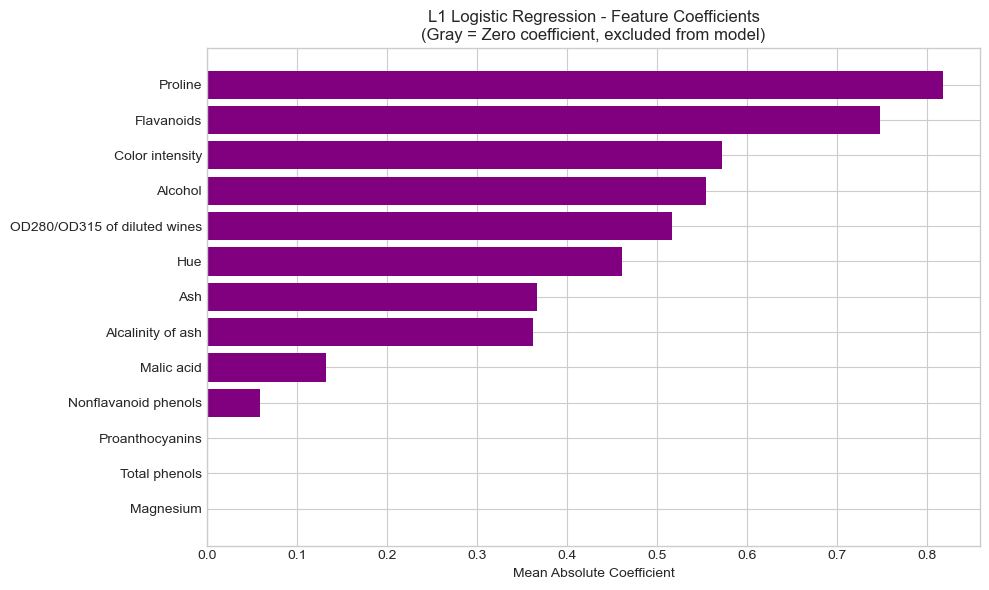


Features with zero coefficient (excluded): 3
Features with non-zero coefficient (selected): 10


In [19]:
# Visualize coefficients
plt.figure(figsize=(10, 6))
coef_sorted = coef_df.sort_values('Coefficient', ascending=True)
colors = ['gray' if x else 'purple' for x in coef_sorted['Is_Zero']]
plt.barh(coef_sorted['Feature'], coef_sorted['Coefficient'], color=colors)
plt.xlabel('Mean Absolute Coefficient')
plt.title('L1 Logistic Regression - Feature Coefficients\n(Gray = Zero coefficient, excluded from model)')
plt.tight_layout()
plt.show()

n_zero = coef_df['Is_Zero'].sum()
print(f"\nFeatures with zero coefficient (excluded): {n_zero}")
print(f"Features with non-zero coefficient (selected): {len(coef_df) - n_zero}")

In [ ]:
# TODO: compute `selector_l1`, `max_iter`, `threshold`
# Name your result: selector_l1, max_iter, threshold, X_selected_l1

---

## 4. Comparing Feature Selection Methods

Let us compare model performance with different feature selection approaches to see which method works best for our dataset.

In [21]:
from sklearn.model_selection import cross_val_score

# Define a classifier for comparison
clf = DecisionTreeClassifier(max_depth=5, random_state=42)

results = {}

# All features
scores_all = cross_val_score(clf, X, y, cv=5, scoring='accuracy')
results['All Features (13)'] = (scores_all.mean(), scores_all.std(), X.shape[1])

# Correlation-based selection
if selected_features_corr:
    scores_corr = cross_val_score(clf, X[selected_features_corr], y, cv=5, scoring='accuracy')
    results['Correlation'] = (scores_corr.mean(), scores_corr.std(), len(selected_features_corr))

# SelectKBest
scores_kbest = cross_val_score(clf, X_selected, y, cv=5, scoring='accuracy')
results['SelectKBest (k=5)'] = (scores_kbest.mean(), scores_kbest.std(), 5)

# Random Forest selection
scores_rf = cross_val_score(clf, X_selected_model, y, cv=5, scoring='accuracy')
results['RandomForest'] = (scores_rf.mean(), scores_rf.std(), X_selected_model.shape[1])

# Display results
results_df = pd.DataFrame.from_dict(results, orient='index', columns=['Mean Accuracy', 'Std', 'Num Features'])
results_df = results_df.sort_values('Mean Accuracy', ascending=False)

print("Comparison of Feature Selection Methods:")
print("="*60)
print(results_df.round(4))

Comparison of Feature Selection Methods:
                   Mean Accuracy     Std  Num Features
SelectKBest (k=5)         0.9165  0.0607             5
RandomForest              0.9105  0.0475             6
Correlation               0.8821  0.0209            10
All Features (13)         0.8654  0.0440            13


In [ ]:
# TODO: draw a `plt.subplots` of `Std`
# Name your result: colors

---

## 5. Choosing the Right Feature Selection Method

Here are some guidelines for selecting the appropriate feature selection method:

![Choosing Methods](https://external-content.duckduckgo.com/iu/?u=https%3A%2F%2Fscikit-learn.org%2F1.3%2F_static%2Fml_map.png&f=1&nofb=1&ipt=14c26cbbe7eb9312ad26abbb2cecbc94e0f951b54da753e96b9fffdc37b7fc8f)

*Consider your data type, problem type, and computational constraints when choosing a method.*

| Data Type | Recommended Method |
| :--- | :--- |
| **Mostly Categorical** | Chi-squared test, tree-based selection |
| **Mostly Numerical** | Correlation, ANOVA, linear models with regularization |
| **Binary Classification** | SVC with L1, Logistic Regression |
| **High Dimensionality** | Tree-based or L1 regularization |
| **Need Speed** | Filter methods (correlation, ANOVA) |
| **Need Accuracy** | Wrapper methods (RFE), embedded methods |

> **Key Takeaway**: Always combine automated feature selection with domain knowledge. Understanding what features mean can help you make better decisions about what to include or exclude.

---

## Summary

In this notebook, we covered:

1. **Why feature selection matters** - Reducing noise, improving accuracy, speeding up training, and preventing overfitting
2. **Statistical methods (Filter)** - Pearson correlation and ANOVA with SelectKBest
3. **Model-based methods (Embedded)** - Tree importances and L1 regularization with SelectFromModel
4. **Comparing methods** - Using cross-validation to evaluate different approaches
5. **Choosing the right method** - Guidelines based on data type and problem requirements

Feature selection is a crucial preprocessing step that can significantly impact your machine learning pipeline's performance.

---

## Exercises

### Exercise 1: Variance Threshold
Use `VarianceThreshold` from sklearn to remove features with low variance. How many features are removed?

In [23]:
# Your code here
# from sklearn.feature_selection import VarianceThreshold
# selector = VarianceThreshold(threshold=0.1)
# ...

In [ ]:
# ═══ CHECKPOINT — "Exercise 2: Recursive Feature Elimination (RFE)" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import warnings
df = pd.read_csv('../../00-data/wine_types.csv')
X = df.drop('Type', axis=1)
y = df['Type']
correlation_matrix = df.corr()
target_correlations = df.corr()['Type'].drop('Type').sort_values(key=abs, ascending=False)
for feature, corr in target_correlations.items():
    strength = 'Strong' if abs(corr) > 0.5 else 'Moderate' if abs(corr) > 0.3 else 'Weak'
    print(f'{feature:25} {corr:8.3f}  ({strength})')
colors = ['forestgreen' if x > 0 else 'crimson' for x in target_correlations]
threshold = 0.3
highly_correlated = target_correlations[abs(target_correlations) > threshold]
selected_features_corr = highly_correlated.index.tolist()
feature_corr = X.corr()
upper_triangle = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool))
high_corr_pairs = []
from sklearn.feature_selection import SelectKBest, f_classif
k_best = SelectKBest(score_func=f_classif, k=5)
k_best.fit(X, y)
p_values = pd.DataFrame({'Feature': X.columns, 'F-Score': k_best.scores_, 'p-value': k_best.pvalues_}).sort_values('p-value')
p_values['Significant'] = p_values['p-value'].apply(lambda x: 'Yes (p<0.05)' if x < 0.05 else 'No')
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
p_values_sorted = p_values.sort_values('F-Score', ascending=True)
colors = ['forestgreen' if x < 0.05 else 'gray' for x in p_values_sorted['p-value']]
X_selected = k_best.transform(X)
selected_mask = k_best.get_support()
selected_features = X.columns[selected_mask].tolist()
from sklearn.tree import DecisionTreeClassifier
pipeline = Pipeline([('select_k', SelectKBest(score_func=f_classif)), ('classifier', DecisionTreeClassifier(random_state=42))])
param_grid = {'select_k__k': [3, 5, 7, 10, 'all'], 'classifier__max_depth': [3, 5, 7, None]}
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='accuracy', return_train_score=True)
grid_search.fit(X, y)
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)
importances = pd.DataFrame({'Feature': X.columns, 'Importance': rf.feature_importances_}).sort_values('Importance', ascending=False)
importances['Cumulative'] = importances['Importance'].cumsum()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
importances_sorted = importances.sort_values('Importance', ascending=True)
importances_desc = importances.sort_values('Importance', ascending=False).reset_index(drop=True)
n_features_90 = (importances_desc['Cumulative'] < 0.9).sum() + 1
from sklearn.feature_selection import SelectFromModel
selector = SelectFromModel(RandomForestClassifier(n_estimators=100, random_state=42), threshold='mean')
X_selected_model = selector.fit_transform(X, y)
selected_mask = selector.get_support()
selected_features_rf = X.columns[selected_mask].tolist()
from sklearn.linear_model import LogisticRegression
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
lr_l1 = LogisticRegression(penalty='l1', solver='saga', max_iter=1000, random_state=42, C=1.0)
lr_l1.fit(X_scaled, y)
coef_mean = np.abs(lr_l1.coef_).mean(axis=0)
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': coef_mean, 'Is_Zero': coef_mean == 0}).sort_values('Coefficient', ascending=False)
coef_sorted = coef_df.sort_values('Coefficient', ascending=True)
colors = ['gray' if x else 'purple' for x in coef_sorted['Is_Zero']]
n_zero = coef_df['Is_Zero'].sum()
selector_l1 = SelectFromModel(LogisticRegression(penalty='l1', solver='saga', max_iter=1000, random_state=42), threshold=0.01)
X_selected_l1 = selector_l1.fit_transform(X_scaled, y)
selected_mask_l1 = selector_l1.get_support()
selected_features_l1 = X.columns[selected_mask_l1].tolist()
from sklearn.model_selection import cross_val_score
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
results = {}
scores_all = cross_val_score(clf, X, y, cv=5, scoring='accuracy')
results['All Features (13)'] = (scores_all.mean(), scores_all.std(), X.shape[1])
if selected_features_corr:
    scores_corr = cross_val_score(clf, X[selected_features_corr], y, cv=5, scoring='accuracy')
    results['Correlation'] = (scores_corr.mean(), scores_corr.std(), len(selected_features_corr))
scores_kbest = cross_val_score(clf, X_selected, y, cv=5, scoring='accuracy')
results['SelectKBest (k=5)'] = (scores_kbest.mean(), scores_kbest.std(), 5)
scores_rf = cross_val_score(clf, X_selected_model, y, cv=5, scoring='accuracy')
results['RandomForest'] = (scores_rf.mean(), scores_rf.std(), X_selected_model.shape[1])
results_df = pd.DataFrame.from_dict(results, orient='index', columns=['Mean Accuracy', 'Std', 'Num Features'])
results_df = results_df.sort_values('Mean Accuracy', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['steelblue' if x < results_df['Mean Accuracy'].max() else 'green' for x in results_df['Mean Accuracy']]

print("Checkpoint restored. Ready for: Exercise 2: Recursive Feature Elimination (RFE)")

### Exercise 2: Recursive Feature Elimination (RFE)

RFE is a **wrapper method** that recursively removes features and builds a model on remaining features.

Apply RFE with a Random Forest classifier. Select the top 5 features.

In [24]:
# Your code here
# from sklearn.feature_selection import RFE
# rfe = RFE(estimator=RandomForestClassifier(random_state=42), n_features_to_select=5)
# rfe.fit(X, y)
# print("Selected features:", X.columns[rfe.support_].tolist())

### Exercise 3: Compare Chi-Squared vs ANOVA
Try using `chi2` instead of `f_classif` with SelectKBest. Note: chi2 requires non-negative features, so you may need to use MinMaxScaler first. Compare the selected features.

In [25]:
# Your code here
# from sklearn.preprocessing import MinMaxScaler
# from sklearn.feature_selection import chi2
# ...

---

## How this is used in real work

Wide, short data is everywhere: assay panels, sensor arrays, clickstream aggregates, anything with feature-store sprawl. Selection cuts cost and latency as much as it cuts overfitting. Getting the cross-validation wrong here is how a model reaches production with a reported score it never had.

## Where this goes next

**C6** makes 'inside the pipeline' the default rather than something to remember.